# Phase II: Data Collection and Exploratory Data Analysis

### Project: Inflation and Monthly S&P 500 Returns (2017–2026)

**Group:** Jaemin Kwon (jk2975), Mike Zhang (hz727)

**Course:** INFO 2950, Fall 2026 | **Project workspace:** https://github.com/jkwon128/INFO2950-Project

## Research Question

Inflation is one of the most closely followed numbers in the U.S. economy, and it is widely
assumed to matter for the stock market. The usual reasoning runs through valuation. When
inflation rises, the Federal Reserve tends to raise short-term interest rates. A higher interest
rate means investors discount future corporate earnings more heavily, so they pay less today for
the same stream of future profits. Rising input costs can squeeze profit margins at the same
time. Both arguments point the same way: months with higher inflation should tend to have weaker
stock returns.

The reasoning is not airtight. Inflation often rises because demand is strong, and strong demand
is good for corporate earnings. So the sign of the relationship is genuinely an empirical
question rather than something we can settle by argument.

We study that question using monthly U.S. data. Our outcome is the monthly price return on the
S&P 500. Our main explanatory variable is the year-over-year inflation rate computed from the
Consumer Price Index. We ask:

> **How does U.S. inflation relate to monthly S&P 500 price returns between January 2017 and
> September 2026? In particular, do months with higher year-over-year headline CPI inflation
> show lower returns, does the same pattern hold when food and energy are excluded, and how do
> consumers' expectations of future inflation compare with inflation that actually occurred?**

Our aim is to describe how one widely reported indicator lines up with stock market performance,
and to be honest about how much of the month-to-month movement in returns it fails to explain.

A note on scope. Our analysis is observational, and we compare inflation and returns measured
over the same calendar month. We therefore describe associations. We do not claim that inflation
causes returns to change, and we do not propose a trading strategy.

## Data Collection and Cleaning

### Collection

We combine data from two meaningfully distinct public sources. All files were downloaded as
`.csv` and are stored unmodified in `data/raw/`; every transformation below begins from those
files.

**Source 1 — Federal Reserve Economic Data (FRED), Federal Reserve Bank of St. Louis.** We
downloaded three series directly from their FRED series pages:

| Series ID | Measures | Frequency | Produced by |
|---|---|---|---|
| `SP500` | S&P 500 closing index level (price only, no dividends) | Daily | S&P Dow Jones Indices LLC |
| `CPIAUCNS` | CPI for All Urban Consumers, All Items, not seasonally adjusted | Monthly | U.S. Bureau of Labor Statistics |
| `CPILFENS` | CPI for All Urban Consumers, All Items Less Food and Energy, not seasonally adjusted | Monthly | U.S. Bureau of Labor Statistics |

**Source 2 — University of Michigan Surveys of Consumers**, distributed through FRED:

| Series ID | Measures | Frequency | Produced by |
|---|---|---|---|
| `MICH` | Median expected price change over the next 12 months | Monthly | University of Michigan Surveys of Consumers |

These are distinct sources rather than one dataset under different names. The S&P 500 series is
market transaction data from a private index provider. The two CPI series come from a government
price survey. `MICH` is a household opinion survey run by a university. What lets us put them
together is the calendar month, and the combination is the point: no single one of these files
can tell us how inflation and stock returns move relative to each other.

Two choices in the selection are worth explaining. We use the not-seasonally-adjusted CPI
because we compute year-over-year changes, and a twelve-month change already removes the seasonal
pattern that seasonal adjustment exists to remove. We use the price-only S&P 500 series because
that is what FRED publishes; the consequences of leaving out dividends are discussed under Data
Limitations.

### Cleaning

The steps below turn four raw files into one analysis-ready table where each row is a calendar
month. We save intermediate files along the way so that later phases do not have to rebuild
everything from scratch.

#### Step 1 — Import libraries and read the raw files

We import the libraries used throughout, then read all four files without altering them, so that
our starting point is exactly what we downloaded.

**Where the data files are.** The cell below reads the four raw `.csv` files from the
location named in `DATA`. By default this is our project repository on GitHub, so the
notebook runs anywhere with an internet connection, including a fresh Google Colab
session, without any files needing to be uploaded first. `pd.read_csv` accepts a web
address in place of a file path, so nothing else in the notebook has to change.

To run instead from a copy of the data stored alongside this notebook, comment out the
GitHub line and uncomment `DATA = "data/raw"`.

In [1]:
# Libraries for handling and reshaping the data
import pandas as pd
import numpy as np

# Libraries for the plots in the exploratory section
import matplotlib.pyplot as plt
import seaborn as sns

# Regression tool used in HW3 and in lecture
from sklearn.linear_model import LinearRegression

# Display settings so that tables and figures are readable in this notebook
%matplotlib inline
pd.set_option("display.width", 100)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

# Where the raw data files live.
# Default: read from our project repository, which works anywhere including Google Colab.
# To read from a local data/raw folder next to this notebook, swap which line is commented.
# DATA = "data/raw"
DATA = "https://raw.githubusercontent.com/jkwon128/INFO2950-Project/main/data/raw"

# Read the four files exactly as downloaded from FRED
sp500_raw = pd.read_csv(f"{DATA}/SP500.csv")        # daily S&P 500 closing level
headline_raw = pd.read_csv(f"{DATA}/CPIAUCNS.csv")  # monthly headline CPI index
core_raw = pd.read_csv(f"{DATA}/CPILFENS.csv")      # monthly core CPI index
mich_raw = pd.read_csv(f"{DATA}/MICH.csv")          # monthly expected inflation, percent

print("All four raw files loaded from:", DATA)

All four raw files loaded from: https://raw.githubusercontent.com/jkwon128/INFO2950-Project/main/data/raw


All four files loaded without error, so we can move on to looking at what is in them.

#### Step 2 — Initial inspection

We check the dimensions, the first rows and the number of missing values in each file before
changing anything. Any surprise then appears here, where we can explain it, rather than later in
a merge where it would be harder to notice.

In [2]:
# Check dimensions, first rows, and missing values for each raw file
for name, frame in [("SP500 daily", sp500_raw),
                    ("CPIAUCNS headline CPI monthly", headline_raw),
                    ("CPILFENS core CPI monthly", core_raw),
                    ("MICH expected inflation monthly", mich_raw)]:
    print("=" * 70)
    print(name, "- shape:", frame.shape)
    print(frame.head(3))
    print("Missing values per column:")
    print(frame.isna().sum())

SP500 daily - shape: (2599, 2)
  observation_date    SP500
0       2016-10-14  2132.98
1       2016-10-17  2126.50
2       2016-10-18  2139.60
Missing values per column:
observation_date     0
SP500               96
dtype: int64
CPIAUCNS headline CPI monthly - shape: (141, 2)
  observation_date  CPIAUCNS
0       2015-01-01   233.707
1       2015-02-01   234.722
2       2015-03-01   236.119
Missing values per column:
observation_date    0
CPIAUCNS            1
dtype: int64
CPILFENS core CPI monthly - shape: (141, 2)
  observation_date  CPILFENS
0       2015-01-01   239.248
1       2015-02-01   240.083
2       2015-03-01   241.067
Missing values per column:
observation_date    0
CPILFENS            1
dtype: int64
MICH expected inflation monthly - shape: (119, 2)
  observation_date  MICH
0       2016-10-01   2.4
1       2016-11-01   2.4
2       2016-12-01   2.2
Missing values per column:
observation_date    0
MICH                0
dtype: int64


Four things stand out, and each one shapes a later step.

The S&P 500 file has 2,599 daily rows running from 14 October 2016 to 30 September 2026, and 96
of them have no closing price. These are market holidays: FRED keeps the calendar row but there
is no price because the exchange was shut. They are not errors, and we drop them rather than
filling them in. Inventing a price for a day with no trading would mean fabricating data.

Both CPI files have 141 monthly rows from January 2015 to September 2026, and both are missing
exactly one value. Step 2b identifies which month, because the answer turns out to matter.

The `MICH` file has 119 monthly rows from October 2016 to August 2026 and no missing values. It
starts later and ends a month earlier than the CPI series, so expected inflation will be
available for fewer months than realized inflation.

Finally, the four files are at different frequencies, one daily and three monthly, so they cannot
be merged until the S&P 500 series has been reduced to one row per month.

#### Step 2b — Finding the missing CPI month

A single missing value is worth tracking down rather than dropping quietly, because which month
is missing determines which months we are able to analyze.

In [3]:
# Find the rows of each CPI series that have no published index value
print("Headline CPI months with no value:")
print(headline_raw[headline_raw["CPIAUCNS"].isna()])
print()
print("Core CPI months with no value:")
print(core_raw[core_raw["CPILFENS"].isna()])

Headline CPI months with no value:
    observation_date  CPIAUCNS
129       2025-10-01       NaN

Core CPI months with no value:
    observation_date  CPILFENS
129       2025-10-01       NaN


Both series are missing **October 2025**, and the gap is real rather than a download error. The
federal government shutdown that began in October 2025 suspended Bureau of Labor Statistics data
collection, and the October 2025 CPI was never published for either index. The value does not
exist, so re-downloading cannot recover it and we do not impute it.

This has two consequences. October 2025 has no inflation rate and therefore cannot enter our
analysis sample. The twelve-month change for October 2026 would also be unavailable, since
October 2025 would be its base month; that does not affect us because our data end in September
2026, but it would matter for anyone extending this work. We record the exclusion explicitly in
Step 7 rather than letting the row vanish.

#### Step 3 — Standardize names, dates and calendar columns

We give the columns short descriptive names and convert the date columns to datetime objects. We
then create a `Year` column and a `Month` column for each file, which is how we will line the
four series up with each other.

We also create a single `month_index` column, defined as `Year * 12 + Month`. This is simply a
running count of months, so that the month before any given month is always one lower and the
same month a year earlier is always twelve lower. Having that number makes the comparisons in
Steps 4 and 5 straightforward, because a shift in time becomes ordinary arithmetic followed by a
merge.

Note that we do not need to convert the value columns to numbers. The blank entries in the raw
files are read as missing values automatically, which the inspection in Step 2 already confirmed.

In [4]:
# Rename columns so that all four frames follow the same pattern
sp500 = sp500_raw.rename(columns={"observation_date": "date", "SP500": "sp500_close"})
headline = headline_raw.rename(columns={"observation_date": "date", "CPIAUCNS": "headline_cpi"})
core = core_raw.rename(columns={"observation_date": "date", "CPILFENS": "core_cpi"})
mich = mich_raw.rename(columns={"observation_date": "date", "MICH": "expected_inflation_pct"})

# Convert dates, then add Year, Month and a running month counter to each frame
for frame in (sp500, headline, core, mich):
    frame["date"] = pd.to_datetime(frame["date"])
    frame["Year"] = frame["date"].dt.year
    frame["Month"] = frame["date"].dt.month
    # month_index counts months continuously, so one month back is always one lower
    frame["month_index"] = frame["Year"] * 12 + frame["Month"]

# Confirm the result
print("S&P 500 data types:")
print(sp500.dtypes)
print()
print(sp500.head(3))
print()
print(headline.head(3))

S&P 500 data types:
date           datetime64[us]
sp500_close           float64
Year                    int32
Month                   int32
month_index             int32
dtype: object

        date  sp500_close  Year  Month  month_index
0 2016-10-14      2132.98  2016     10        24202
1 2016-10-17      2126.50  2016     10        24202
2 2016-10-18      2139.60  2016     10        24202

        date  headline_cpi  Year  Month  month_index
0 2015-01-01       233.707  2015      1        24181
1 2015-02-01       234.722  2015      2        24182
2 2015-03-01       236.119  2015      3        24183


Every frame now has a datetime `date` column, a `Year`, a `Month` and a `month_index`, and the
value columns are stored as numbers. The column names are consistent across all four, which is
what makes the merges later on readable.

#### Step 4 — Reduce daily prices to monthly returns

Our unit of observation is the calendar month, but the S&P 500 series is daily, so we reduce it
to one row per month.

We take the closing price on the **last trading day of each month** rather than the monthly
average. A monthly average blends prices from across the month and does not correspond to a
return any investor could have earned. Using month-end closes lets us define the monthly return
as the percent change from one month-end price to the next, which is the standard definition of a
monthly price return.

To find the last trading day we group by year and month and take the latest date in each group,
then merge that date back onto the daily data to recover its closing price. To compute the return
we make a second copy of the monthly table with `month_index` increased by one, which lines each
month up against the month before it.

In [5]:
# Drop the 96 market-holiday rows that have no closing price
sp500_trading = sp500.dropna(subset=["sp500_close"])
print("Daily rows before dropping holidays:", len(sp500))
print("Daily rows after dropping holidays:", len(sp500_trading))

# Find the last trading date within each calendar month
month_ends = (sp500_trading
              .groupby(["Year", "Month", "month_index"], as_index=False)["date"]
              .max()
              .rename(columns={"date": "last_trading_date"}))

# Merge that date back onto the daily data to pick up the closing price on that day
monthly_price = month_ends.merge(
    sp500_trading[["date", "sp500_close"]],
    left_on="last_trading_date", right_on="date", how="left").drop(columns="date")

# Build a copy labelled one month later, so each month lines up with the previous month
previous_month = monthly_price[["month_index", "sp500_close"]].copy()
previous_month["month_index"] = previous_month["month_index"] + 1
previous_month = previous_month.rename(columns={"sp500_close": "previous_close"})

# Monthly price return (%) = percent change from the previous month-end close
monthly_price = monthly_price.merge(previous_month, on="month_index", how="left")
monthly_price["sp500_return_pct"] = ((monthly_price["sp500_close"] - monthly_price["previous_close"])
                                     / monthly_price["previous_close"]) * 100

monthly_price = monthly_price.sort_values("month_index").reset_index(drop=True)
print("\nMonthly price observations:", len(monthly_price))
print(monthly_price.head(5))

Daily rows before dropping holidays: 2599
Daily rows after dropping holidays: 2503

Monthly price observations: 120
   Year  Month  month_index last_trading_date  sp500_close  previous_close  sp500_return_pct
0  2016     10        24202        2016-10-31      2126.15             NaN               NaN
1  2016     11        24203        2016-11-30      2198.81         2126.15          3.417445
2  2016     12        24204        2016-12-30      2238.83         2198.81          1.820075
3  2017      1        24205        2017-01-31      2278.87         2238.83          1.788434
4  2017      2        24206        2017-02-28      2363.64         2278.87          3.719826


The 2,599 daily rows become 120 monthly observations once the 96 holiday rows are removed and one
row is kept per month. The first month, October 2016, has no return because there is no earlier
month-end close to compare against, which is why its `sp500_return_pct` is missing.

October 2016 is also a partial month in the raw file, since the series begins on 14 October. Its
closing price on 31 October is still a genuine month-end price, so the November 2016 return
computed from it is valid. We nevertheless begin the analysis sample in January 2017, as set out
in Step 7, which starts the sample on a clean calendar-year boundary and means every month we
analyze is a complete one.

#### Step 5 — Compute year-over-year inflation

Inflation is not the level of the CPI but its rate of change. Following our mentor's advice in
Phase I we use the year-over-year change, which is the percent change in the index from the same
month one year earlier. A twelve-month change is less sensitive to short-term monthly movements
than a month-over-month change, and it is the form in which inflation is normally reported.

For month $t$ the year-over-year rate in percent is

$$\text{inflation}_t = \frac{\text{CPI}_t - \text{CPI}_{t-12}}{\text{CPI}_{t-12}} \times 100$$

We build this with the same approach used for returns in Step 4: make a copy of the CPI table
with `month_index` increased by twelve and merge it back, so that each month sits alongside its
own base month. Doing it this way keeps the alignment visible, and a month with no data produces
a missing rate rather than being silently skipped.

In [6]:
# Build a year-over-year percent change for one CPI series
def add_year_over_year(frame, level_column, new_column):
    """Return a monthly table with a year-over-year percent change column.

    frame        : a monthly CPI frame with month_index, Year, Month and a level column
    level_column : name of the CPI level column
    new_column   : name to give the new percent change column
    """
    result = frame[["month_index", "Year", "Month", level_column]].copy()

    # Copy the same data labelled twelve months later, so each month meets its base year
    base = result[["month_index", level_column]].copy()
    base["month_index"] = base["month_index"] + 12
    base = base.rename(columns={level_column: "base_value"})

    result = result.merge(base, on="month_index", how="left")
    result[new_column] = (result[level_column] - result["base_value"]) / result["base_value"] * 100
    return result.drop(columns="base_value")

# Year-over-year inflation for the headline and core CPI series
headline_yoy = add_year_over_year(headline, "headline_cpi", "headline_yoy_pct")
core_yoy = add_year_over_year(core, "core_cpi", "core_yoy_pct")

# The expectations series is already expressed as a percent, so it only needs its key columns
expected_monthly = mich[["month_index", "expected_inflation_pct"]].copy()

print("Headline inflation, first months with a computable rate:")
print(headline_yoy.dropna(subset=["headline_yoy_pct"]).head(3))
print("\nMonths with no computable headline inflation rate:",
      headline_yoy["headline_yoy_pct"].isna().sum())

Headline inflation, first months with a computable rate:
    month_index  Year  Month  headline_cpi  headline_yoy_pct
12        24193  2016      1       236.916          1.373087
13        24194  2016      2       237.111          1.017800
14        24195  2016      3       238.132          0.852536

Months with no computable headline inflation rate: 13


Year-over-year inflation can be computed from January 2016 onwards, since the CPI series starts
in January 2015 and those first twelve months serve only as base values. Thirteen months have no
computable rate: the twelve months of 2015, which have no base year within our download, and
October 2025, whose index was never published. The same holds for core CPI. This is the behaviour
we want, in that a month with no data yields a missing rate instead of a wrong one.

#### Step 6 — Check each monthly series before merging

Two problems would quietly corrupt a merge: duplicate months, which would multiply rows, and
unexpected date coverage. We check for both, then save the cleaned monthly pieces.

In [7]:
# Check each cleaned monthly series for duplicate months and report its coverage
for name, frame in [("S&P 500 monthly", monthly_price),
                    ("Headline inflation", headline_yoy),
                    ("Core inflation", core_yoy),
                    ("Expected inflation", expected_monthly)]:
    duplicates = frame["month_index"].duplicated().sum()
    print(f"{name:22} rows={len(frame):4d}  duplicate months={duplicates}  "
          f"month_index {frame['month_index'].min()} to {frame['month_index'].max()}")

# Save the cleaned monthly pieces so that later phases need not rebuild them
monthly_price.to_csv("monthly_sp500_cleaned.csv", index=False)
headline_yoy.to_csv("monthly_headline_inflation_cleaned.csv", index=False)
core_yoy.to_csv("monthly_core_inflation_cleaned.csv", index=False)
expected_monthly.to_csv("monthly_expected_inflation_cleaned.csv", index=False)
print("\nFour intermediate cleaned files saved.")

S&P 500 monthly        rows= 120  duplicate months=0  month_index 24202 to 24321
Headline inflation     rows= 141  duplicate months=0  month_index 24181 to 24321
Core inflation         rows= 141  duplicate months=0  month_index 24181 to 24321
Expected inflation     rows= 119  duplicate months=0  month_index 24202 to 24320

Four intermediate cleaned files saved.


No series contains a duplicate month, so each month appears exactly once in each frame and the
merge in Step 7 cannot multiply rows. The coverage confirms what Step 2 showed: the S&P 500 and
CPI series both run to September 2026, while expected inflation stops in August 2026.

#### Step 7 — Merge into the analysis-ready dataset

We now merge the four monthly series on `month_index`, restrict the result to the analysis
window, and drop the months that cannot be analyzed. Every exclusion is recorded.

Our window runs from **January 2017 to September 2026**. The start is set by the S&P 500 series,
which begins in mid-October 2016, so January 2017 is the first clean calendar-year boundary after
that point. The end is the last month for which both the CPI and the S&P 500 are available. The
window was fixed by what data exist, not by looking at any result.

In [8]:
# Merge the four monthly series on the shared month counter
merged = (monthly_price[["month_index", "Year", "Month", "last_trading_date",
                         "sp500_close", "sp500_return_pct"]]
          .merge(headline_yoy[["month_index", "headline_cpi", "headline_yoy_pct"]],
                 on="month_index", how="left")
          .merge(core_yoy[["month_index", "core_cpi", "core_yoy_pct"]],
                 on="month_index", how="left")
          .merge(expected_monthly, on="month_index", how="left")
          .sort_values("month_index")
          .reset_index(drop=True))

print("Rows after merging all four series:", len(merged))
print("Missing values per column:")
print(merged.isna().sum())

# Restrict to the analysis window, using the month counter for January 2017 and September 2026
start_index = 2017 * 12 + 1
end_index = 2026 * 12 + 9
window = merged[(merged["month_index"] >= start_index) &
                (merged["month_index"] <= end_index)]
print("\nRows inside the January 2017 to September 2026 window:", len(window))

# A month can be analyzed only if it has both a return and a headline inflation rate
analysis_df = window.dropna(subset=["sp500_return_pct", "headline_yoy_pct"]).reset_index(drop=True)
excluded = window[window["sp500_return_pct"].isna() | window["headline_yoy_pct"].isna()]

print("Months in the final analysis dataset:", len(analysis_df))
print("Months excluded from the window:", len(excluded))
print("\nExcluded month(s):")
print(excluded[["Year", "Month", "sp500_return_pct", "headline_yoy_pct"]])

# Save the merged table, the final dataset and the record of what was excluded
merged.to_csv("merged_all_months.csv", index=False)
analysis_df.to_csv("analysis_dataset.csv", index=False)
excluded.to_csv("excluded_months.csv", index=False)
print("\nFinal analysis dataset and exclusion log saved.")
print(analysis_df.head(5))

Rows after merging all four series: 120
Missing values per column:
month_index               0
Year                      0
Month                     0
last_trading_date         0
sp500_close               0
sp500_return_pct          1
headline_cpi              1
headline_yoy_pct          1
core_cpi                  1
core_yoy_pct              1
expected_inflation_pct    1
dtype: int64

Rows inside the January 2017 to September 2026 window: 117
Months in the final analysis dataset: 116
Months excluded from the window: 1

Excluded month(s):
     Year  Month  sp500_return_pct  headline_yoy_pct
108  2025     10          2.268684               NaN

Final analysis dataset and exclusion log saved.
   month_index  Year  Month last_trading_date  sp500_close  sp500_return_pct  headline_cpi  \
0        24205  2017      1        2017-01-31      2278.87          1.788434       242.839   
1        24206  2017      2        2017-02-28      2363.64          3.719826       243.603   
2        24207  20

The merge produces one row per month with no duplication, which confirms that the month counter
worked as a key.

The window contains 117 months. One of them, October 2025, is excluded because its CPI was never
published during the government shutdown, which leaves **116 months in the final analysis
dataset**. We save that exclusion to `excluded_months.csv` so that it forms part of the project
record rather than a remark in the text.

Expected inflation is missing for September 2026 because the Michigan series ends in August 2026.
We keep that month rather than dropping it, since both of our main variables are present. Any
analysis involving expected inflation therefore uses 115 months instead of 116, and we report
that sample size wherever it applies.

## Data Description

*The format of this section follows Gebru, T., Morgenstern, J., Vecchione, B., Vaughan, J. W.,
Wallach, H., Daumé III, H., & Crawford, K. (2021). Datasheets for datasets. Communications of the
ACM, 64(12), 86–92. https://arxiv.org/abs/1803.09010*

This describes our analysis-ready dataset, `analysis_dataset.csv`, rather than the raw downloads.

### What are the observations (rows) and the attributes (columns)?

The dataset has **116 rows**, one for each calendar month from January 2017 to September 2026
except October 2025. Each row represents one month of the U.S. economy and the U.S. stock market.

There are **11 columns**:

| Column | Meaning | Units |
|---|---|---|
| `month_index` | Running month counter, `Year * 12 + Month` | Count |
| `Year` | Calendar year | Year |
| `Month` | Calendar month | 1–12 |
| `last_trading_date` | Final trading day of that month | Date |
| `sp500_close` | S&P 500 closing level on that day | Index points |
| `sp500_return_pct` | Outcome variable: price return from the previous month-end close | Percent |
| `headline_cpi` | Headline CPI-U index level, all items | Index, 1982–84 = 100 |
| `headline_yoy_pct` | Main explanatory variable: year-over-year change in headline CPI | Percent |
| `core_cpi` | Core CPI-U index level, less food and energy | Index, 1982–84 = 100 |
| `core_yoy_pct` | Year-over-year change in core CPI | Percent |
| `expected_inflation_pct` | Median expected price change over the next 12 months | Percent |

All four analysis variables are measured in percent, so a one-unit change always means one
percentage point.

### Why was this dataset created?

We built it to examine whether months of higher U.S. inflation coincide with weaker S&P 500
returns. No public file contains both inflation and monthly equity returns on a shared monthly
key, so the dataset exists in order to place a government price survey, a market index and a
household survey on the same monthly footing. It was assembled for an INFO 2950 course project
at Cornell University and is intended to support descriptive comparison and simple regression.

### How did you create this dataset? What tools, procedures and data sources did you use?

We downloaded four `.csv` files: `SP500`, `CPIAUCNS` and `CPILFENS` from FRED, and the University
of Michigan `MICH` series distributed through FRED. We combined them in this notebook using
Python and `pandas`. The procedure is the seven steps above: inspect the files, standardize names
and calendar columns, reduce daily prices to month-end closes and compute monthly returns,
compute year-over-year inflation, check each monthly series for duplicates, and merge on the
month counter. Figures use `matplotlib` and `seaborn`, and the regressions use
`LinearRegression` from `scikit-learn`. We collected no data ourselves, and all four sources are
free to access.

### Who funded the creation of the dataset?

The underlying series come from publicly funded or publicly accessible institutions. The Bureau
of Labor Statistics, a federal agency, produces both CPI series. The Federal Reserve Bank of St.
Louis distributes them through FRED along with the S&P 500 series. S&P Dow Jones Indices LLC
produces the index itself. The University of Michigan Surveys of Consumers produces the
expectations series. We assembled the merged dataset with no external funding.

### What processes might have influenced what data was observed and recorded, and what was not?

Several decisions, none of them ours, shape what this dataset contains.

What counts as inflation is itself a methodological choice. The CPI tracks the price of a fixed
basket of goods and services for urban consumers, so it reflects BLS decisions about basket
composition, geographic coverage, substitution and quality adjustment. Urban consumers are about
93% of the U.S. population, which means rural price experience is underweighted.

October 2025 is missing because of a political event rather than a measurement failure. The
government shutdown suspended BLS collection and that month was never published. Our data
therefore have a gap created by how the statistical system is funded and governed.

The S&P 500 series is a price index, so dividends are invisible to us. Total investor returns,
which include reinvested dividends, are higher than what we observe, historically by roughly two
percentage points a year. The index also covers only large publicly traded U.S. companies, so
private firms, small caps and non-U.S. markets are outside its scope by construction.

Aggregating to months conceals timing within the month. A month-end-to-month-end return cannot
distinguish a steady climb from a crash followed by a recovery.

Finally, expectations are self-reported. `MICH` records what survey respondents say they expect,
which may reflect general feeling about the economy as much as a considered forecast, and it is
reported as a median across respondents rather than a consensus view.

### What preprocessing was done, and how did the data come to be in the form that you are using?

1. Four raw `.csv` files were read from `data/raw/` without modification.
2. Shapes, first rows and missing-value counts were checked for each file, and the one missing
   CPI month was identified as October 2025.
3. Columns were renamed consistently, dates converted to datetime objects, and `Year`, `Month`
   and a running `month_index` added to each file.
4. The 96 market-holiday rows were dropped, the last trading day of each month identified, and
   the monthly price return computed as the percent change between consecutive month-end closes.
5. Year-over-year inflation was computed for headline and core CPI by merging each month against
   the same month twelve months earlier. Expected inflation was used as published.
6. Each monthly series was checked for duplicate months, none of which were found, and four
   intermediate cleaned files were saved.
7. The four series were merged on the month counter, restricted to January 2017 to September
   2026, and the one month without CPI was dropped and logged.

No values were imputed at any stage.

### If people are involved, were they aware of the data collection, and what purpose did they expect the data to be used for?

Two of our sources ultimately rest on people. CPI prices are collected by BLS staff from retail
establishments and service providers rather than from individuals, and no personal information is
involved. The Michigan series comes from a voluntary household telephone survey in which
respondents agree to take part and are told that the survey concerns consumer attitudes toward
the economy. Results are published only in aggregate. Respondents would reasonably have expected
their answers to be used for economic research and public reporting, which is how we use them.
Our dataset holds no individual-level records, so no respondent can be identified from it.

### Where can your raw source data be found?

- S&P 500 index level (`SP500`): https://fred.stlouisfed.org/series/SP500
- Headline CPI, all items, not seasonally adjusted (`CPIAUCNS`): https://fred.stlouisfed.org/series/CPIAUCNS
- Core CPI, less food and energy, not seasonally adjusted (`CPILFENS`): https://fred.stlouisfed.org/series/CPILFENS
- University of Michigan inflation expectations (`MICH`): https://fred.stlouisfed.org/series/MICH
- Our raw downloads, cleaning code and cleaned dataset: https://github.com/jkwon128/INFO2950-Project

> ⚠️ **Before submitting:** the four raw `.csv` files and this notebook must be pushed to the
> repository above, and both project mentors given access, before the link in this section meets
> the Phase II requirement. As of this draft the files exist locally only.

## Data Limitations

Our sources are of high quality, but there are limitations that change how the results should be
read.

**Dividends are excluded.** We measure price returns, so our figures understate what an investor
actually earned, historically by around two percentage points a year. Every statement we make
about returns means price returns. This matters most for the average level of returns. It matters
less for the relationship with inflation, unless dividend yields themselves move with inflation,
which they may.

**October 2025 is missing, and the reason is itself a limitation.** The shutdown suspended BLS
collection and the month was never published. Dropping it rather than imputing keeps the data
honest, but it leaves a hole created by a political decision rather than by chance. If inflation
behaved unusually that month, its absence is not random.

**Consecutive months are highly dependent.** Any two adjacent months share eleven of the twelve
months of price change that go into their year-over-year rates. Standard regression inference
assumes independent observations, so ordinary p-values computed on this data would be too small
and would overstate confidence. We return to this in our preregistration and do not describe any
result as statistically significant without a method that accounts for it.

**The sample is short and covers an unusual decade.** Our window contains the COVID-19 crash and
rebound of 2020 and the inflation surge of 2021 to 2023. Those episodes supply a large share of
our variation, so our estimates describe this period rather than a general regularity. March 2020
alone produces the most extreme return in the dataset.

**Contemporaneous matching limits what we can claim.** We match inflation to returns within the
same calendar month, which our mentor confirmed is appropriate for studying contemporaneous
association. But a month's CPI is published partway through the following month, so investors did
not know that figure while the month's returns were being generated. Our design can speak to
co-movement, not to prediction or to market reaction.

**Inflation is one of many forces acting on share prices.** Interest rate policy, corporate
earnings, employment, fiscal policy and global shocks all move markets, and several of them move
alongside inflation. We do not control for any of them, so an association we observe may reflect
those other forces rather than inflation itself. This is the main reason we avoid causal
language.

**Core CPI leaves out costs people really face.** Removing food and energy produces a smoother
series, but food and energy are genuine household expenses and genuine business input costs. Core
inflation is a different measure, not a better one.

### How these limitations could affect people

Claims about inflation and the stock market can influence how ordinary savers behave. A reader
who treated a negative association as a reason to sell shares when inflation rises would be
acting on a contemporaneous correlation estimated from 116 months of an unusual period, using
returns that omit dividends, with standard errors that understate uncertainty. The risk is not
hypothetical: investors who leave the market on signals like this tend to miss rebounds, and our
own data show the worst month in the sample, March 2020, immediately followed by the best one.
Our final report will state plainly that these results are descriptive and are not investment
advice.

## Exploratory Data Analysis

The exploratory work below has two aims: to describe each variable on its own, and to describe
how pairs of variables move together. We have chosen a small number of figures that each answer a
question rather than producing every chart available to us.

One constraint we have placed on ourselves is worth stating up front. Our two preregistered
analyses in Part 2 are regressions of monthly return on headline and on core inflation. To keep
that preregistration meaningful, **we do not fit either of those models anywhere in this
section**. The scatterplots below appear without fitted lines, and the two regressions we do run,
in EDA 8 and EDA 9, have an inflation measure rather than returns as the outcome, so neither is
among our hypotheses. We do report descriptive correlations, because the rubric asks us to
examine connections between pairs of relevant variables and because the directions of our
hypotheses were fixed in Phase I before this dataset was assembled.

### EDA 1 — Summary statistics

We begin with typical values and spread for the four analysis variables.

In [9]:
# Summary statistics for the four analysis variables
analysis_vars = ["sp500_return_pct", "headline_yoy_pct", "core_yoy_pct", "expected_inflation_pct"]
summary = analysis_df[analysis_vars].describe().round(3)
print("Sample:", len(analysis_df), "months, from",
      f"{analysis_df['Year'].iloc[0]}-{analysis_df['Month'].iloc[0]:02d}", "to",
      f"{analysis_df['Year'].iloc[-1]}-{analysis_df['Month'].iloc[-1]:02d}")
print(summary)

# Skewness indicates whether each distribution is symmetric
print("\nSkewness:")
print(analysis_df[analysis_vars].skew().round(3))

# Save the summary table for reuse in the final report
summary.to_csv("summary_statistics.csv")

Sample: 116 months, from 2017-01 to 2026-09
       sp500_return_pct  headline_yoy_pct  core_yoy_pct  expected_inflation_pct
count           116.000           116.000       116.000                 115.000
mean              1.146             3.351         3.150                   3.528
std               4.491             2.040         1.468                   1.025
min             -12.512             0.118         1.187                   2.100
25%              -1.008             2.066         2.111                   2.700
50%               1.790             2.720         2.614                   3.100
75%               3.630             3.709         4.002                   4.500
max              12.684             9.060         6.631                   6.600

Skewness:
sp500_return_pct         -0.427
headline_yoy_pct          1.300
core_yoy_pct              0.910
expected_inflation_pct    0.772
dtype: float64


Monthly S&P 500 price returns average **1.15%**, with a median of **1.79%** and a standard
deviation of **4.49** percentage points. The median sits above the mean and skewness is
**−0.43**, so the distribution is **left-skewed**: most months are modestly positive, but the
occasional very bad month is considerably worse than a typical good month is good. Returns range
from **−12.51%** to **+12.68%**, so a single month can move more than ten percent either way.

Headline year-over-year inflation averages **3.35%**, with a median of **2.72%**, a minimum of
**0.12%** and a maximum of **9.06%**. Here the mean exceeds the median and skewness is **+1.30**,
so the distribution is **right-skewed**. Inflation sat near 2% for most of the decade and was
pulled upward by the surge of 2021 to 2023.

Core inflation is similar on average, at a mean of **3.15%** and a median of **2.61%**, but it is
noticeably less volatile, with a standard deviation of **1.47** against **2.04** for headline, and
it peaks lower, at **6.63%** rather than 9.06%. That is precisely what removing food and energy
is meant to achieve.

Expected inflation averages **3.53%**, slightly above average realized headline inflation, and is
the steadiest of the three measures, with a standard deviation of **1.03** and a floor of
**2.1%**. Its count is **115** rather than 116 because the Michigan series ends in August 2026.

Two observations matter for our question. Returns are far more variable than inflation, with a
standard deviation of 4.5 points against 2.0, so inflation would have to be very strongly related
to returns in order to account for much of their movement. And both inflation measures are
right-skewed, which means a small number of high-inflation months will carry unusual weight in
any slope we estimate.

### EDA 2 — Correlations between the variables

Next we look at how the four variables move together. These are descriptive correlation
coefficients rather than fitted models or tests.

In [10]:
# Correlation matrix among the four analysis variables
correlations = analysis_df[analysis_vars].corr().round(3)
print("Correlations, January 2017 to September 2026 (n = 116):")
print(correlations)

Correlations, January 2017 to September 2026 (n = 116):
                        sp500_return_pct  headline_yoy_pct  core_yoy_pct  expected_inflation_pct
sp500_return_pct                   1.000            -0.159        -0.122                  -0.035
headline_yoy_pct                  -0.159             1.000         0.920                   0.701
core_yoy_pct                      -0.122             0.920         1.000                   0.664
expected_inflation_pct            -0.035             0.701         0.664                   1.000


The results fall into two groups.

Returns correlate negatively but weakly with every inflation measure: **−0.159** with headline
inflation, **−0.122** with core, and **−0.035** with expected inflation. All three carry the sign
we hypothesized in Phase I, and all three are small. A correlation of −0.159 implies that headline
inflation accounts for roughly 2.5% of the variation in monthly returns, leaving almost all of it
unexplained. The ordering is itself suggestive, since the association weakens as the measure moves
further from realized prices, and we raise it in our questions for reviewers.

The inflation measures, by contrast, correlate strongly with one another. Headline and core
inflation correlate **0.920**, while expected inflation correlates **0.701** with headline and
**0.664** with core. The 0.920 figure has a direct bearing on our design, because headline and
core carry nearly the same information across this period, which makes our two preregistered
analyses closely related rather than independent. We say so explicitly in Part 2. It also means
the two measures should not appear in a single regression, where they would be severely
collinear.

### EDA 3 — The three inflation measures over time

Plotting inflation over time shows which episodes drive the variation in our main explanatory
variable.

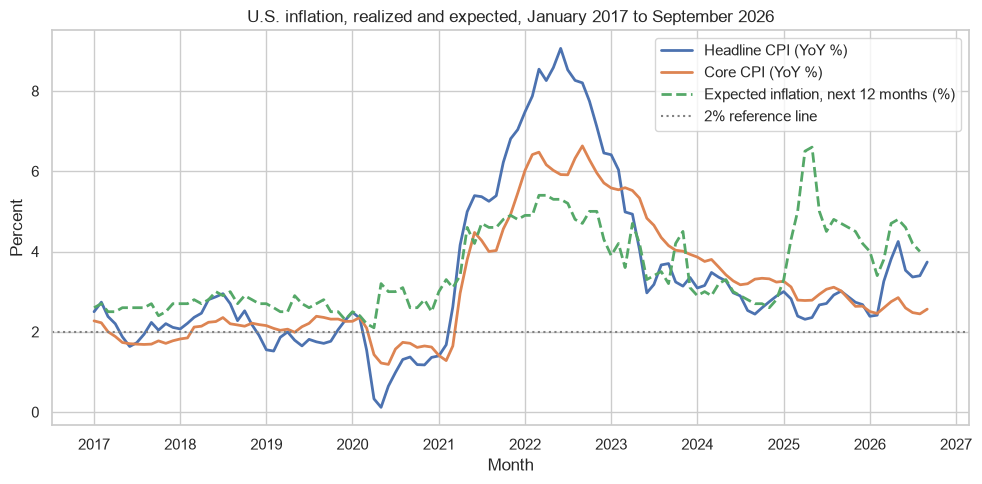

In [11]:
# Build a monthly date column so the figures can use a proper time axis
plot_df = analysis_df.copy()
plot_df["month_date"] = pd.to_datetime(dict(year=plot_df["Year"], month=plot_df["Month"], day=1))

# Plot the three inflation measures together for direct comparison
plt.figure(figsize=(10, 5))
plt.plot(plot_df["month_date"], plot_df["headline_yoy_pct"], label="Headline CPI (YoY %)", linewidth=2)
plt.plot(plot_df["month_date"], plot_df["core_yoy_pct"], label="Core CPI (YoY %)", linewidth=2)
plt.plot(plot_df["month_date"], plot_df["expected_inflation_pct"],
         label="Expected inflation, next 12 months (%)", linewidth=2, linestyle="--")
plt.axhline(2, color="grey", linestyle=":", label="2% reference line")
plt.xlabel("Month")
plt.ylabel("Percent")
plt.title("U.S. inflation, realized and expected, January 2017 to September 2026")
plt.legend()
plt.tight_layout()
plt.show()

The decade divides into three phases. From 2017 through 2020 all three measures sit close to the
2% line, with headline inflation falling to its sample minimum of 0.12% during the 2020 shutdown.
From 2021 into mid-2022 headline inflation climbs steeply to its peak of 9.06% in June 2022, with
core peaking lower and slightly later. From 2023 onward both realized measures fall back toward
3%.

Two features matter for the analysis. Headline is more volatile than core throughout, with
sharper peaks and troughs, which is unsurprising given that the components it adds are the
volatile ones. And expected inflation is visibly smoother than either realized measure, sitting
above them for much of the sample and barely responding to the collapse in realized prices during
2020. Households appear to hold a persistent floor in their expectations that realized inflation
does not share, which is a finding in its own right and the subject of EDA 9.

### EDA 4 — Monthly returns over time

The same view of our outcome variable shows where the extreme months fall.

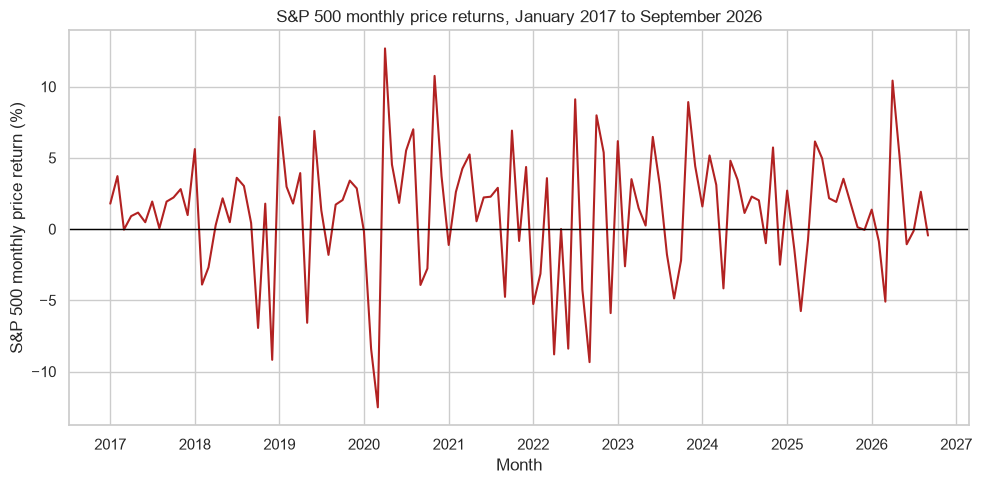

Three worst months:
 Year  Month  sp500_return_pct  headline_yoy_pct
 2020      3        -12.511932          1.539327
 2022      9         -9.339570          8.201670
 2018     12         -9.177696          1.910159

Three best months:
 Year  Month  sp500_return_pct  headline_yoy_pct
 2020      4         12.684410          0.329097
 2020     11         10.754566          1.174536
 2026      4         10.423343          3.810845


In [12]:
# Plot monthly returns over time with a zero reference line
plt.figure(figsize=(10, 5))
plt.plot(plot_df["month_date"], plot_df["sp500_return_pct"], color="firebrick", linewidth=1.5)
plt.axhline(0, color="black", linewidth=1)
plt.xlabel("Month")
plt.ylabel("S&P 500 monthly price return (%)")
plt.title("S&P 500 monthly price returns, January 2017 to September 2026")
plt.tight_layout()
plt.show()

# Identify the most extreme months so that they can be discussed directly
print("Three worst months:")
print(analysis_df.nsmallest(3, "sp500_return_pct")[
    ["Year", "Month", "sp500_return_pct", "headline_yoy_pct"]].to_string(index=False))
print("\nThree best months:")
print(analysis_df.nlargest(3, "sp500_return_pct")[
    ["Year", "Month", "sp500_return_pct", "headline_yoy_pct"]].to_string(index=False))

Returns oscillate around zero without a visible trend, which is what we expect from a return
series rather than an index level. The extremes are more informative than the pattern.

The worst month is **March 2020 at −12.51%**, the COVID-19 crash, and headline inflation that
month was **1.54%**, close to the sample average. The best month is **April 2020 at +12.68%**,
the rebound, with inflation at its sample low of **0.33%**. The one extreme month that does
coincide with high inflation is **September 2022 at −9.34%**, when inflation stood at **8.20%**.

This is the most important thing our exploratory work reveals about the research question. The
largest movements in our outcome were driven by a pandemic, an event with no particular
connection to inflation. Two of the three most extreme months occurred while inflation was
unremarkable. Any association we estimate has to compete with that noise, which goes a long way
toward explaining why the correlations in EDA 2 are so weak. It also means March and April 2020
will exert heavy influence on our preregistered regressions, and it is why we committed in
advance to keeping genuine extreme values rather than trimming them.

### EDA 5 — Distributions of the two main variables

Histograms let us see the shapes implied by the summary statistics.

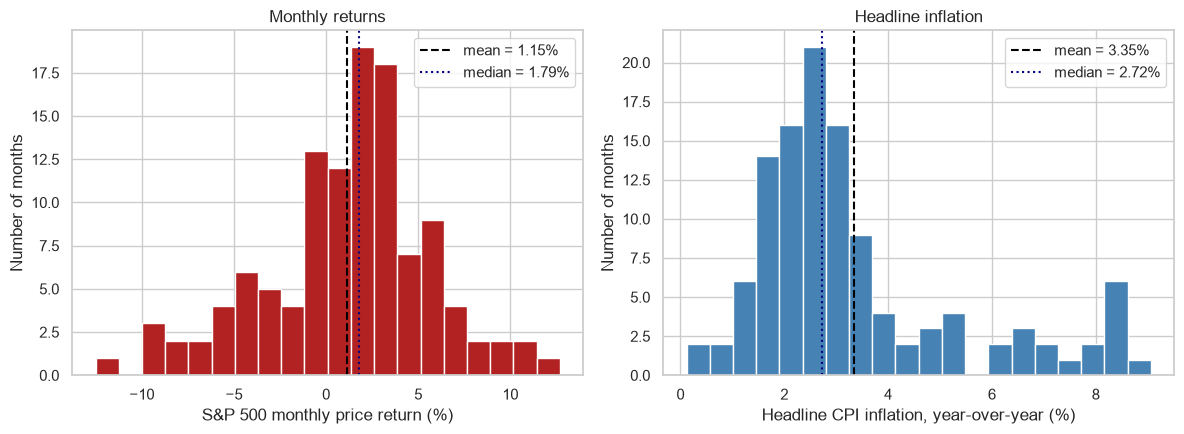

In [13]:
# Two histograms side by side: the outcome and the main explanatory variable
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].hist(analysis_df["sp500_return_pct"], bins=20, color="firebrick", edgecolor="white")
axes[0].axvline(analysis_df["sp500_return_pct"].mean(), color="black", linestyle="--",
                label=f"mean = {analysis_df['sp500_return_pct'].mean():.2f}%")
axes[0].axvline(analysis_df["sp500_return_pct"].median(), color="navy", linestyle=":",
                label=f"median = {analysis_df['sp500_return_pct'].median():.2f}%")
axes[0].set_xlabel("S&P 500 monthly price return (%)")
axes[0].set_ylabel("Number of months")
axes[0].set_title("Monthly returns")
axes[0].legend()

axes[1].hist(analysis_df["headline_yoy_pct"], bins=20, color="steelblue", edgecolor="white")
axes[1].axvline(analysis_df["headline_yoy_pct"].mean(), color="black", linestyle="--",
                label=f"mean = {analysis_df['headline_yoy_pct'].mean():.2f}%")
axes[1].axvline(analysis_df["headline_yoy_pct"].median(), color="navy", linestyle=":",
                label=f"median = {analysis_df['headline_yoy_pct'].median():.2f}%")
axes[1].set_xlabel("Headline CPI inflation, year-over-year (%)")
axes[1].set_ylabel("Number of months")
axes[1].set_title("Headline inflation")
axes[1].legend()

plt.tight_layout()
plt.show()

The two shapes are opposites, and both are relevant.

Returns are left-skewed and roughly bell-shaped around a positive centre. Most months fall between
−3% and +5%, with a short tail of severe losses reaching −12.5%. The mean sits below the median,
pulled down by those few bad months. This asymmetry is characteristic of equity returns: frequent
modest gains interrupted by rare sharp losses.

Headline inflation is right-skewed and clearly not bell-shaped. Most months lie between 1% and
3%, with a long thin tail reaching 9%, and the mean sits above the median because of that tail.
In practical terms our explanatory variable has very few observations at high values. The months
above 6% inflation are a small group, and they will carry disproportionate weight when a slope is
estimated, which is a reason to examine the scatterplot rather than relying on a single summary
number.

### EDA 6 — Headline inflation against returns

This is the central pair of variables for our research question. As explained above, the scatter
appears without a fitted line, because fitting that line is our first preregistered analysis.

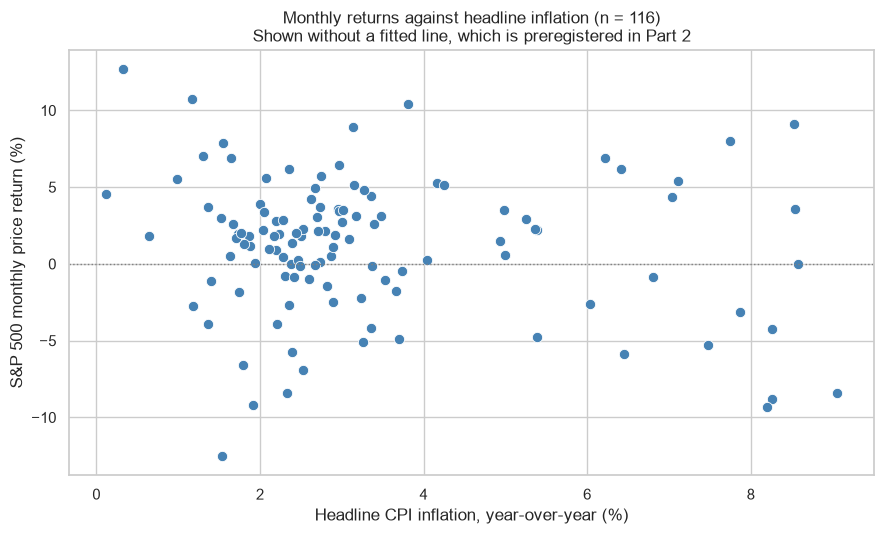

Returns by inflation regime, descriptive only, no test performed:
                   count   mean  median    std
inflation_regime                              
high (above 3%)       46  0.966   1.905  4.889
low (3% or below)     70  1.264   1.790  4.242


In [14]:
# Scatterplot of the central relationship, deliberately without a fitted line
plt.figure(figsize=(9, 5.5))
sns.scatterplot(data=analysis_df, x="headline_yoy_pct", y="sp500_return_pct", s=55,
                color="steelblue", edgecolor="white")
plt.axhline(0, color="grey", linewidth=1, linestyle=":")
plt.xlabel("Headline CPI inflation, year-over-year (%)")
plt.ylabel("S&P 500 monthly price return (%)")
plt.title("Monthly returns against headline inflation (n = 116)\n"
          "Shown without a fitted line, which is preregistered in Part 2")
plt.tight_layout()
plt.show()

# Descriptive comparison of months above and below 3% inflation
analysis_df["inflation_regime"] = np.where(analysis_df["headline_yoy_pct"] > 3,
                                           "high (above 3%)", "low (3% or below)")
print("Returns by inflation regime, descriptive only, no test performed:")
print(analysis_df.groupby("inflation_regime")["sp500_return_pct"]
      .agg(["count", "mean", "median", "std"]).round(3))

The scatter shows a wide vertical spread at every level of inflation. Around 2% inflation, monthly
returns run from roughly −13% to +13%, and above 8% they still include both gains and losses.
Nothing resembling a tight relationship is visible, which agrees with the correlation of −0.159
from EDA 2.

The regime comparison makes the same point in numbers. The 46 months with headline inflation above
3% averaged a **0.97%** return, against **1.26%** for the 70 months at or below 3%. The difference
of about 0.3 percentage points runs in the direction we hypothesized, but it is small beside a
standard deviation of roughly 4.5 points within each group. The medians, moreover, run the other
way, at 1.91% in high-inflation months against 1.79% in low-inflation months. When the mean and
the median disagree about the direction of a difference, that difference is being produced by a
few extreme observations rather than by any shift in the typical month. We report both figures
rather than selecting whichever suits our hypothesis.

### EDA 7 — Core inflation against returns

The same view using core inflation, which is our second preregistered relationship and so is also
shown without a fitted line.

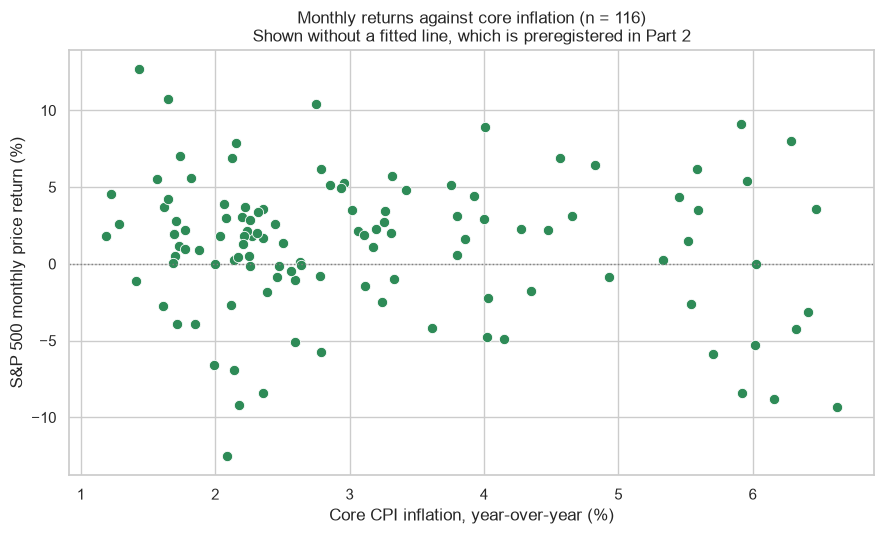

In [15]:
# Scatterplot for the core inflation relationship, also without a fitted line
plt.figure(figsize=(9, 5.5))
sns.scatterplot(data=analysis_df, x="core_yoy_pct", y="sp500_return_pct", s=55,
                color="seagreen", edgecolor="white")
plt.axhline(0, color="grey", linewidth=1, linestyle=":")
plt.xlabel("Core CPI inflation, year-over-year (%)")
plt.ylabel("S&P 500 monthly price return (%)")
plt.title("Monthly returns against core inflation (n = 116)\n"
          "Shown without a fitted line, which is preregistered in Part 2")
plt.tight_layout()
plt.show()

The core scatter resembles the headline scatter with one visible difference: the points are
compressed horizontally, spanning roughly 1.2% to 6.6% rather than 0.1% to 9.1%. That is the lower
volatility of core inflation appearing directly. The vertical spread of returns is unchanged, and
again no clear pattern is apparent, consistent with the slightly weaker correlation of −0.122.

This has a consequence we should anticipate. Because core inflation has a narrower range while
returns vary just as much, the fitted slope on core will likely be steeper than the slope on
headline even though its correlation is weaker, since the same vertical spread is being divided by
a narrower horizontal one. We note it here so that we interpret the two preregistered slopes
correctly rather than treating the larger number as the stronger relationship.

### EDA 8 — How closely do headline and core inflation track each other?

EDA 2 reported a correlation of 0.920 between the two inflation measures. Since our project treats
headline as primary and core as a secondary comparison, it matters how much independent
information core actually contributes. This regression is not one of our preregistered analyses,
because the outcome here is core inflation rather than returns.

In [16]:
# Regress core inflation on headline inflation using the method practiced in HW3.
# Note: this is NOT a preregistered analysis; the outcome is core inflation, not returns.
reg_df = analysis_df.dropna(subset=["headline_yoy_pct", "core_yoy_pct"])
x_measures = reg_df[["headline_yoy_pct"]]   # predictor must be two-dimensional
y_measures = reg_df["core_yoy_pct"]

model_measures = LinearRegression()
model_measures.fit(x_measures, y_measures)

slope_measures = model_measures.coef_[0]
intercept_measures = model_measures.intercept_
r2_measures = model_measures.score(x_measures, y_measures)

print("Regression of core inflation on headline inflation")
print("Observations:", len(reg_df))
print("Slope:", round(slope_measures, 4))
print("Intercept:", round(intercept_measures, 4))
print("R-squared:", round(r2_measures, 4))

Regression of core inflation on headline inflation
Observations: 116
Slope: 0.6617
Intercept: 0.9325
R-squared: 0.8456


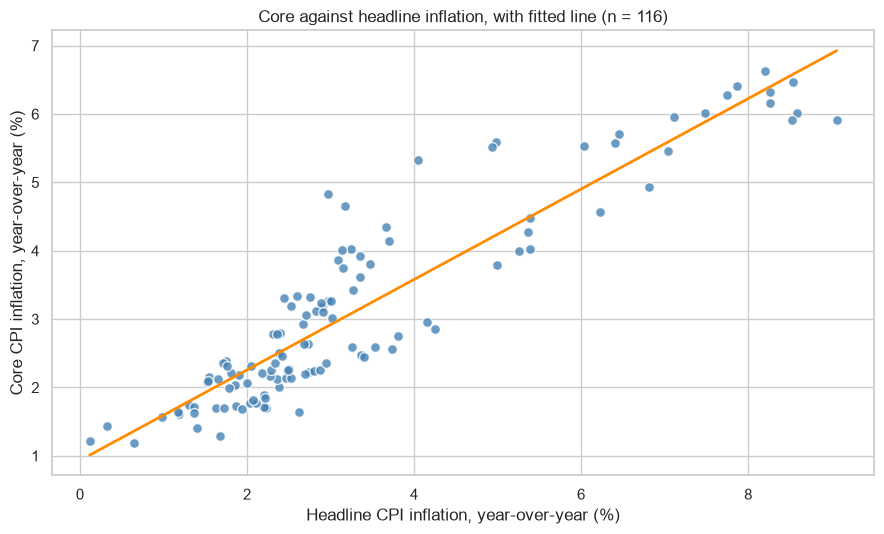

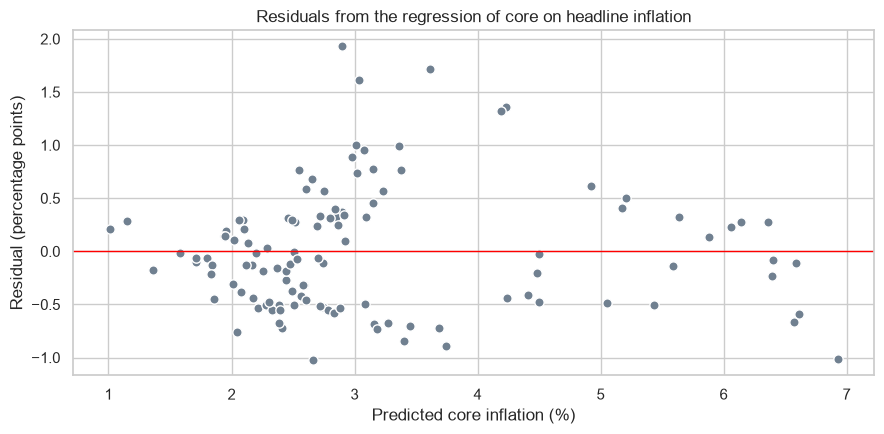

In [17]:
# Plot the fitted relationship between the two inflation measures
plt.figure(figsize=(9, 5.5))
sns.regplot(data=reg_df, x="headline_yoy_pct", y="core_yoy_pct",
            scatter_kws={"s": 50, "color": "steelblue", "edgecolor": "white"},
            line_kws={"color": "darkorange", "linewidth": 2}, ci=None)
plt.xlabel("Headline CPI inflation, year-over-year (%)")
plt.ylabel("Core CPI inflation, year-over-year (%)")
plt.title("Core against headline inflation, with fitted line (n = 116)")
plt.tight_layout()
plt.show()

# Residual plot to check whether a straight line describes the relationship adequately
predicted_core = model_measures.predict(x_measures)
residuals = y_measures - predicted_core

plt.figure(figsize=(9, 4.5))
plt.scatter(predicted_core, residuals, s=45, color="slategrey", edgecolor="white")
plt.axhline(0, color="red", linewidth=1)
plt.xlabel("Predicted core inflation (%)")
plt.ylabel("Residual (percentage points)")
plt.title("Residuals from the regression of core on headline inflation")
plt.tight_layout()
plt.show()

The fitted model is

$$\widehat{\text{core inflation}} = 0.93 + 0.66 \times \text{headline inflation}$$

Read in the usual three parts: a one percentage point increase in year-over-year headline CPI
inflation corresponds to a **0.66 percentage point** increase in year-over-year core CPI
inflation, on average. The relationship is strong, with **R² = 0.846**, so headline inflation
accounts for about 85% of the variation in core inflation.

The slope being below one is the substantive result. Core inflation moves in the same direction as
headline but by roughly two thirds as much, which is the quantitative form of the statement that
core is the smoother measure. The intercept of 0.93 says that when headline inflation is zero, core
inflation is still running near 1%, which is consistent with food and energy prices falling while
other prices continue to rise.

The residual plot shows no fan shape, so constant variance looks like a reasonable assumption here.
The residuals are not randomly scattered either. They move in runs, with stretches of consecutive
months on the same side of zero, which is the serial correlation described under Data Limitations
appearing directly in a figure. It does not undermine the descriptive slope, but it is the reason
we are cautious about significance testing on monthly macroeconomic data.

For our project the implication is that core adds limited independent information over this period.
Our two preregistered analyses should be presented as two views of one relationship rather than as
an independent replication.

### EDA 9 — Do consumers' expectations match realized inflation?

Our third Phase I idea concerned inflation expectations. EDA 2 showed they correlate only −0.035
with returns, the weakest of the three measures. Before setting that idea aside we examine how
expectations relate to realized inflation, which helps explain why they behave as they do. This is
again not a preregistered analysis.

In [18]:
# Regress expected inflation on realized headline inflation.
# Note: not a preregistered analysis; the outcome is expectations, not returns.
exp_df = analysis_df.dropna(subset=["headline_yoy_pct", "expected_inflation_pct"])
x_expect = exp_df[["headline_yoy_pct"]]
y_expect = exp_df["expected_inflation_pct"]

model_expect = LinearRegression()
model_expect.fit(x_expect, y_expect)

print("Regression of expected inflation on realized headline inflation")
print("Observations:", len(exp_df))
print("Slope:", round(model_expect.coef_[0], 4))
print("Intercept:", round(model_expect.intercept_, 4))
print("R-squared:", round(model_expect.score(x_expect, y_expect), 4))

# How often did households expect more inflation than actually occurred?
above = (exp_df["expected_inflation_pct"] > exp_df["headline_yoy_pct"]).sum()
print(f"\nMonths where expected inflation exceeded realized inflation: {above} of {len(exp_df)}")
print("Mean expected inflation:", round(exp_df["expected_inflation_pct"].mean(), 2), "%")
print("Mean realized headline inflation:", round(exp_df["headline_yoy_pct"].mean(), 2), "%")

Regression of expected inflation on realized headline inflation
Observations: 115
Slope: 0.3508
Intercept: 2.3534
R-squared: 0.492

Months where expected inflation exceeded realized inflation: 78 of 115
Mean expected inflation: 3.53 %
Mean realized headline inflation: 3.35 %


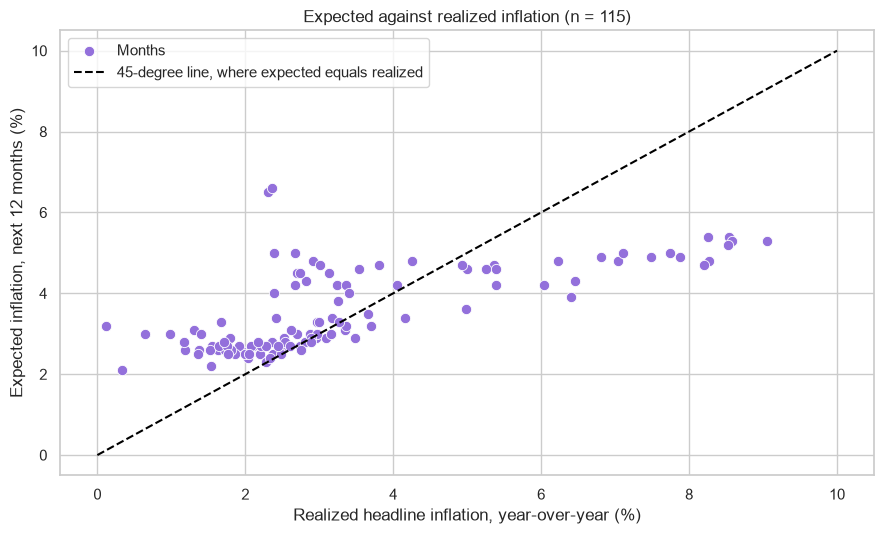

In [19]:
# Compare expected and realized inflation directly, with a 45-degree reference line
plt.figure(figsize=(9, 5.5))
sns.scatterplot(data=exp_df, x="headline_yoy_pct", y="expected_inflation_pct", s=55,
                color="mediumpurple", edgecolor="white", label="Months")
plt.plot([0, 10], [0, 10], color="black", linestyle="--", linewidth=1.5,
         label="45-degree line, where expected equals realized")
plt.xlabel("Realized headline inflation, year-over-year (%)")
plt.ylabel("Expected inflation, next 12 months (%)")
plt.title("Expected against realized inflation (n = 115)")
plt.legend()
plt.tight_layout()
plt.show()

The fitted model is

$$\widehat{\text{expected inflation}} = 2.35 + 0.35 \times \text{realized headline inflation}$$

A one percentage point increase in realized headline inflation corresponds to only a **0.35
percentage point** increase in expected inflation, on average, with **R² = 0.492**. Expectations
move with realized inflation, but they respond by far less than one for one.

The intercept and the 45-degree plot tell the more interesting part of the story. An intercept of
**2.35** means that even with no realized inflation at all, households expect about 2.4% over the
coming year, so expectations have a floor. And in **78 of 115 months**, or roughly two thirds,
expected inflation exceeded realized headline inflation. On the figure most points lie above the
45-degree line when realized inflation is low and below it when realized inflation is high, which
is the signature of a measure that is anchored and slow to adjust rather than one tracking current
prices.

For our project this means expectations are genuinely a different variable rather than a proxy for
realized inflation, and their very weak correlation with returns is consistent with their being
anchored, since a variable that barely moves cannot explain one that moves a great deal. This
supports our mentor's advice to keep headline CPI as the primary measure and treat expectations as
a descriptive comparison, and we do not preregister it.

### What our exploratory analysis changed

The exploratory work confirmed the general direction of our research question while sharpening it
in four ways.

First, the question is unchanged in direction but more modest in ambition. All three inflation
measures correlate negatively with returns, as Phase I anticipated, but all three correlations are
weak, at −0.159, −0.122 and −0.035. We have revised the framing so that it asks explicitly how much
variation inflation leaves unexplained, rather than implying that inflation is a major driver.

Second, we now expect confounding from the pandemic to dominate. Two of our three most extreme
months occurred at ordinary inflation levels. We added this to Data Limitations and will discuss
March and April 2020 explicitly in the final report rather than allowing those points to drive a
slope unremarked.

Third, headline and core are close to being the same variable here, with a correlation of 0.920 and
an R² of 0.846. We have rewritten our second preregistration to describe itself as a related view
rather than an independent test, and we will not place both measures in one model.

Fourth, expectations have been demoted from a candidate hypothesis to a descriptive comparison, on
the evidence that they are anchored, with a slope of 0.35 and an intercept of 2.35, and essentially
uncorrelated with returns.

Our data description needed no revision. No additional data were collected after the initial
download, and the variable definitions it gives are the ones used throughout.

## Questions for Reviewers

These questions came out of our group discussion after we reviewed the exploratory results
together.

1. March 2020 at −12.51% and April 2020 at +12.68% are our two most extreme returns, and both
   occurred at near-average inflation. We committed in advance to keeping genuine extreme values.
   Is that the right call for the preregistered regressions, or would you expect us to add a
   sensitivity analysis excluding 2020 as a clearly labelled amendment?
2. Our year-over-year windows overlap, so consecutive months are highly dependent and ordinary
   p-values would be too small. Is reporting the slope, R² and a clear caveat sufficient for this
   course, or should we use a dependence-robust method such as Newey–West standard errors in
   Phase III?
3. Headline and core inflation correlate 0.920 in our sample. Is it still worth preregistering both
   as separate analyses, or would a stronger second hypothesis be something structurally different,
   such as comparing high- and low-inflation months using a dummy variable as in the ice cream
   example from class?
4. October 2025 CPI was never published because of the government shutdown. We drop the month and
   log it. Is that the treatment you would expect, and should the shutdown be discussed as a
   data-governance limitation in the final report or simply noted as a gap?
5. Our returns are price-only and so understate investor returns by roughly two percentage points a
   year, which our mentor approved in Phase I. For the final report, is a stated caveat enough, or
   should we attempt to reconstruct total returns?
6. Given how weak the bivariate associations are, would you recommend adding a control variable such
   as the unemployment rate or a policy interest rate in Phase III, or keeping the project focused
   on the simple inflation and return relationship and spending the remaining effort on careful
   interpretation?

# Part 2: Preregistration of Analyses

We preregister the two analyses below and commit to reporting both in our final report whatever
the results turn out to be, including weak, null or opposite-direction findings.

**On ordering, stated plainly.** The directions of both hypotheses were fixed in Phase I, before
this dataset was assembled, on the basis of the reasoning given below. Neither regression has been
fitted. The exploratory section deliberately shows both relationships as scatterplots without
fitted lines, and the two regressions we did run, in EDA 8 and EDA 9, take an inflation measure as
the outcome rather than returns. We have, however, seen the descriptive correlations of −0.159 and
−0.122, so we already expect both slopes to be negative and small. We state that openly rather than
claiming an innocence we do not have.

**Rules fixed in advance.** Both analyses use the 116 monthly observations from January 2017 to
September 2026 contained in `analysis_dataset.csv`. The window is set by data availability alone.
We keep all genuine extreme returns, including March and April 2020. We do not impute the missing
October 2025 observation. We will not alter the sample, the variables or the method after seeing
the results, and any change we are later asked to make will be dated and labelled as an amendment.

---

### Preregistration Statement 1 — Headline inflation and monthly returns

**Hypothesis.** Months with higher year-over-year headline CPI inflation have lower S&P 500 monthly
price returns. We expect a negative slope.

*Reasoning.* Standard asset-pricing logic offers two channels. The first is a discount-rate
channel: higher inflation leads the Federal Reserve to raise short-term interest rates, which
raises the rate at which investors discount expected future earnings and therefore lowers the price
they will pay for them today. The second is a margin channel: rising input prices compress profit
margins where firms cannot pass costs on in full. Both imply a negative association. We also
acknowledge a competing mechanism, since inflation often rises when demand is strong and strong
demand supports earnings, which is why we treat a positive or zero slope as a fully reportable
outcome rather than a failure.

**Proposed analysis.** Using the 116 monthly observations, with one row per calendar month, fit a
simple linear regression with an intercept using the `LinearRegression` method practiced in HW3:

$$\text{sp500\_return\_pct}_t = \alpha + \beta_{\text{headline}} \times \text{headline\_yoy\_pct}_t$$

The outcome is the monthly S&P 500 price return in percent and the single predictor is
year-over-year headline CPI inflation in percent. We will report the sample size, the fitted
intercept, the fitted slope, the R², and a scatterplot with the fitted line drawn on it. We will
interpret the slope as follows: a one percentage point increase in year-over-year headline
inflation corresponds to a change of $\beta_{\text{headline}}$ percentage points in the monthly
S&P 500 price return, on average. We will examine whether $\beta_{\text{headline}} < 0$ and will
report the result whichever way it falls. Because our observations are serially dependent, we will
state that ordinary inference understates uncertainty here and will not describe the slope as
statistically significant on the basis of a simple regression alone.

---

### Preregistration Statement 2 — Core inflation and monthly returns

**Hypothesis.** Months with higher year-over-year core CPI inflation also have lower S&P 500
monthly price returns. We expect a negative slope here as well.

*Reasoning.* Neither the discount-rate channel nor the margin channel depends on food and energy
prices specifically. If the association in Statement 1 reflects those channels rather than the
volatile components of the basket, it ought to survive when food and energy are excluded. If it
appears only in headline inflation and vanishes in core, that would point instead toward energy
prices in particular, which would itself be worth reporting.

**Proposed analysis.** Using the same 116 observations and the same method, fit:

$$\text{sp500\_return\_pct}_t = \alpha + \beta_{\text{core}} \times \text{core\_yoy\_pct}_t$$

We will report the same quantities as in Statement 1 and interpret $\beta_{\text{core}}$ in the
same way, as percentage points of monthly return per percentage point of core inflation. We will
examine whether $\beta_{\text{core}} < 0$.

**Two commitments about how we will read this.** First, because headline and core inflation
correlate 0.920 in our sample and headline accounts for 84.6% of the variation in core, this is a
related view of the same relationship rather than an independent replication, and obtaining the
same sign in both is close to guaranteed rather than confirmatory. Second, because core inflation
has a narrower range than headline while returns vary just as much, we expect
$|\beta_{\text{core}}|$ to exceed $|\beta_{\text{headline}}|$ as an arithmetic consequence of
that narrower spread. We will therefore not interpret a larger core slope as a stronger
relationship, and will compare the two models on R² rather than on the size of the slope. We will
not fit headline and core together in one model, since the collinearity would make both
coefficients unreliable.

---

### What we are deliberately not preregistering

Inflation expectations remain a descriptive comparison only. EDA 9 shows that expectations are
anchored, moving just 0.35 percentage points per point of realized inflation and exceeding realized
inflation in roughly two thirds of months, and EDA 2 shows they correlate only −0.035 with returns.
We therefore propose no third test, and we will not convert this comparison into a hypothesis later
without labelling it as an amendment.

We also commit to adding no further predictors, sample restrictions or transformations in search of
a significant result. If we add a control variable in Phase III at our mentor's suggestion, it will
be reported as a clearly labelled extension alongside these two preregistered models, which we will
report regardless.

---

### Questions for Reviewers (Part 2)

1. Are these two hypotheses distinct enough to count as two preregistered analyses, given the 0.920
   correlation between headline and core inflation, or should Statement 2 be replaced with a
   structurally different design such as a high-inflation dummy variable?
2. We commit to reporting the slope and R² while avoiding claims of statistical significance,
   because our year-over-year windows overlap. Is that the right level of caution for this course,
   or would you prefer a formal test reported anyway with the caveat attached?
3. We state openly that we have already seen the descriptive correlations and therefore expect small
   negative slopes. Does disclosing that weaken our preregistration in your view, or is transparency
   about the ordering the better approach?
4. If both slopes turn out small and not clearly distinguishable from zero, what do you consider the
   most useful way to present a null result so that the final report remains informative?